# United States superstore Analysis
## by Apoorava Modi
---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Exploratory Data Analysis (EDA):

## What is Exploratory Data Analysis (EDA)?
Exploratory Data Analysis (EDA) is a crucial initial step in the data science lifecycle. It involves analyzing, visualizing, and summarizing a dataset to understand its underlying structure, identify patterns, detect anomalies (like outliers or missing values), and test hypotheses. 

Instead of jumping straight into complex machine learning models, EDA allows data analysts and scientists to "get a feel" for the data, ensuring that any subsequent modeling is built on a solid, accurate foundation.


## Data Understanding And Cleaning

In [3]:
from pathlib import Path

DATA_PATH = Path("data") / "US Superstore.csv"

store = pd.read_csv(DATA_PATH, encoding="latin1")

In [4]:
print(store.columns)


Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')


In [5]:
store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [6]:
# correcting the column name 

store.columns = store.columns.str.replace(' ','_').str.replace('-','_')

In [7]:
store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row_ID         9994 non-null   int64  
 1   Order_ID       9994 non-null   object 
 2   Order_Date     9994 non-null   object 
 3   Ship_Date      9994 non-null   object 
 4   Ship_Mode      9994 non-null   object 
 5   Customer_ID    9994 non-null   object 
 6   Customer_Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal_Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product_ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub_Category   9994 non-null   object 
 16  Product_Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [8]:
#check shape

print (store.shape)
print ("No. of rows : ",store.shape[0])
print ("No. of columns : ",store.shape[1])

(9994, 21)
No. of rows :  9994
No. of columns :  21


In [9]:
# checking missing values

store.isnull().sum()

Row_ID           0
Order_ID         0
Order_Date       0
Ship_Date        0
Ship_Mode        0
Customer_ID      0
Customer_Name    0
Segment          0
Country          0
City             0
State            0
Postal_Code      0
Region           0
Product_ID       0
Category         0
Sub_Category     0
Product_Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [10]:
# duplicate data checking

print ("Number of duplicated values : ",store.duplicated().sum())

Number of duplicated values :  0


In [11]:
store[['Order_Date','Ship_Date']].head()

,Order_Date,Ship_Date
0,11/8/2016,11/11/2016
1,11/8/2016,11/11/2016
2,6/12/2016,6/16/2016
3,10/11/2015,10/18/2015
4,10/11/2015,10/18/2015


In [12]:
store['Ship_Date']=pd.to_datetime(store['Ship_Date'], format='mixed')

In [13]:
store['Order_Date']= pd.to_datetime(store['Order_Date'],format= 'mixed')

In [14]:
store[['Order_Date','Ship_Date']].dtypes

Order_Date    datetime64[ns]
Ship_Date     datetime64[ns]
dtype: object

In [15]:
# creating day, year, Quarter columns from the order date

store['Day'] = store["Order_Date"].dt.day
store['Year'] = store["Order_Date"].dt.year
store['Quarter'] = store["Order_Date"].dt.quarter
store['Month'] = store["Order_Date"].dt.month

In [16]:
store.columns

Index(['Row_ID', 'Order_ID', 'Order_Date', 'Ship_Date', 'Ship_Mode',
       'Customer_ID', 'Customer_Name', 'Segment', 'Country', 'City', 'State',
       'Postal_Code', 'Region', 'Product_ID', 'Category', 'Sub_Category',
       'Product_Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Day',
       'Year', 'Quarter', 'Month'],
      dtype='object')

In [17]:
# Rounded columns with data type float upto 2 decimal

for i in store.select_dtypes(include = 'float64').columns:
    store[i] = store[i].round(2)

store.select_dtypes(include = 'float64')

,Sales,Discount,Profit
0,261.96,0.00,41.91
1,731.94,0.00,219.58
2,14.62,0.00,6.87
3,957.58,0.45,-383.03
4,22.37,0.20,2.52
...,...,...,...
9989,25.25,0.20,4.10
9990,91.96,0.00,15.63
9991,258.58,0.20,19.39
9992,29.60,0.00,13.32


In [18]:
store.select_dtypes(include = "object").head(2)

,Order_ID,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,State,Region,Product_ID,Category,Sub_Category,Product_Name
0,CA-2016-152156,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase
1,CA-2016-152156,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,..."


In [19]:
store["Row_ID"] = store.Row_ID.astype('str')
store["Postal_Code"] = store.Postal_Code.astype('str')

In [20]:
store.select_dtypes(include = ["float64","int64"]).describe().round(2)

,Sales,Quantity,Discount,Profit
count,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,-6599.98
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.66
75%,209.94,5.00,0.20,29.36
max,22638.48,14.00,0.80,8399.98


# Exploratory data analysis
### Sales, customer, product, regional,and profitability analysis.

In [21]:
# Total Sales

print ('Total Sales:',store.Sales.sum())

Total Sales: 2297200.65


In [22]:
# Average order values

print("average order value : ",store.groupby(['Order_ID']).Sales.sum().mean().round(2))

average order value :  458.61


In [23]:
# highest sales

category_wise_sales = store.groupby(['Category']).Sales.sum()
category_wise_sales

Category
Furniture          741999.73
Office Supplies    719046.90
Technology         836154.02
Name: Sales, dtype: float64

In [24]:
# highest Sub category

sub_category_wise_sales = store.groupby(['Sub_Category']).Sales.sum().sort_values(ascending = False)

In [25]:
sub_category_wise_sales

Sub_Category
Phones         330007.10
Chairs         328449.10
Storage        223843.59
Tables         206965.53
Binders        203412.68
Machines       189238.60
Accessories    167380.31
Copiers        149528.01
Bookcases      114879.98
Appliances     107532.14
Furnishings     91705.12
Paper           78479.24
Supplies        46673.52
Art             27118.80
Envelopes       16476.38
Labels          12486.30
Fasteners        3024.25
Name: Sales, dtype: float64

In [26]:
print ('highest sales category :', category_wise_sales.idxmax())
print ('highest sales category values :', category_wise_sales.max())

highest sales category : Technology
highest sales category values : 836154.02


In [27]:
# sorting 

category_wise_sales.sort_values(ascending = False).head(1)

Category
Technology    836154.02
Name: Sales, dtype: float64

In [28]:
#Lowest sales category

print ('lowest sales category :', category_wise_sales.idxmin())
print ('lowest sales category values :', category_wise_sales.min())

lowest sales category : Office Supplies
lowest sales category values : 719046.9


In [29]:
# Top 10 product by sales?

product_wise_sales = store.groupby (['Product_Name']).Sales.sum()

In [30]:
product_wise_sales.sort_values(ascending = False).head(10)

Product_Name
Canon imageCLASS 2200 Advanced Copier                                          61599.83
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.38
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.48
HON 5400 Series Task Chairs for Big and Tall                                   21870.57
GBC DocuBind TL300 Electric Binding System                                     19823.47
GBC Ibimaster 500 Manual ProClick Binding System                               19024.50
Hewlett Packard LaserJet 3310 Copier                                           18839.68
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.89
GBC DocuBind P400 Electric Binding System                                      17965.07
High Speed Automatic Electric Letter Opener                                    17030.31
Name: Sales, dtype: float64

In [31]:
# bottom 10 product by sales.

product_wise_sales.sort_values(ascending = True).reset_index().head(10)

,Product_Name,Sales
0,Eureka Disposable Bags for Sanitaire Vibra Gro...,1.62
1,Avery 5,5.76
2,Xerox 20,6.48
3,Grip Seal Envelopes,7.07
4,Avery Hi-Liter Pen Style Six-Color Fluorescent...,7.70
5,Avery Hi-Liter Comfort Grip Fluorescent Highli...,7.80
6,Xerox 1989,7.97
7,4009 Highlighters,8.04
8,Stockwell Gold Paper Clips,8.10
9,Newell 308,8.40


In [32]:
# monthly sales trend?

store.pivot_table(index = 'Month',values = 'Sales',aggfunc='sum')

,Sales
Month,
1,94924.87
2,59751.26
3,205005.48
4,137762.13
5,155028.82
6,152718.64
7,147238.07
8,159043.98
9,307649.90


In [33]:
# yearly sales trend?

store.pivot_table(index = 'Year',values = 'Sales',aggfunc='sum')

,Sales
Year,
2014,484247.47
2015,470532.39
2016,609205.74
2017,733215.05


In [34]:
# Quarter sales trend?

store.pivot_table(index = 'Quarter',values = 'Sales',aggfunc='sum')

,Sales
Quarter,
1,359681.61
2,445509.59
3,613931.95
4,878077.50


In [35]:
unique_list = store['Customer_ID'].nunique()
print ("number of unique customer :",unique_list)

number of unique customer : 793


In [36]:
# highest-revenue customers


top_5_customers = store.groupby('Customer_ID')['Profit'].sum().sort_values(ascending=False).head(5)
top_5_customers

Customer_ID
TC-20980    8981.32
RB-19360    6976.09
SC-20095    5757.42
HL-15040    5622.43
AB-10105    5444.81
Name: Profit, dtype: float64

In [37]:
#Lowest contributing segment

store.groupby(['Segment']).Sales.sum().round(2)

Segment
Consumer       1161401.12
Corporate       706146.32
Home Office     429653.21
Name: Sales, dtype: float64

In [38]:
store.groupby(["Customer_Name"]).Sales.mean().round(2).nlargest(10)

Customer_Name
Mitch Willingham        1751.29
Sean Miller             1669.54
Tamara Chand            1587.69
Grant Thornton          1558.53
Tom Ashbrook            1459.56
Hunter Lopez            1170.30
Bill Shonely            1166.85
Christopher Conant      1102.64
Stefanie Holloman       1048.20
Christopher Martinez     895.40
Name: Sales, dtype: float64

In [39]:
store.groupby(["Region"]).Sales.sum().round(2)

Region
Central    501239.76
East       678781.30
South      391721.83
West       725457.76
Name: Sales, dtype: float64

In [40]:
# Lowest profit state? finding 10 lowest states

store.groupby(['State']).Profit.sum().sort_values().head(10).round(2)

State
Texas            -25729.32
Ohio             -16971.38
Pennsylvania     -15560.06
Illinois         -12607.94
North Carolina    -7490.84
Colorado          -6527.88
Tennessee         -5341.67
Arizona           -3427.89
Florida           -3399.26
Oregon            -1190.47
Name: Profit, dtype: float64

## Data Visualization

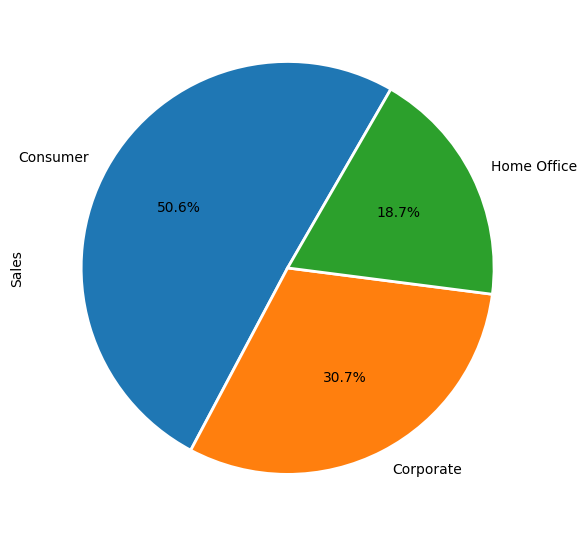

In [41]:
#most valuable segment
plt.figure(figsize=(6,6))
store.groupby(['Segment']).Sales.sum().plot(kind = 'pie',autopct = '%1.1f%%',startangle = 60,wedgeprops = {'edgecolor':'white','linewidth':2})

plt.tight_layout()
plt.show()

In [42]:
# sales by category  

category_wise_sales

Category
Furniture          741999.73
Office Supplies    719046.90
Technology         836154.02
Name: Sales, dtype: float64

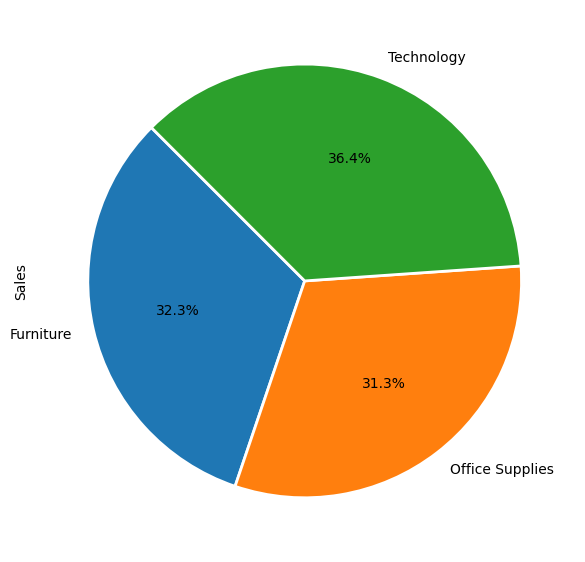

In [43]:
# using pandas plot 
plt.figure(figsize=(6,6))
category_wise_sales.plot(kind = 'pie',autopct= '%1.1f%%',startangle=135,wedgeprops ={'edgecolor':'white','linewidth':2})
plt.xticks(rotation = 0)

plt.tight_layout()
plt.show()

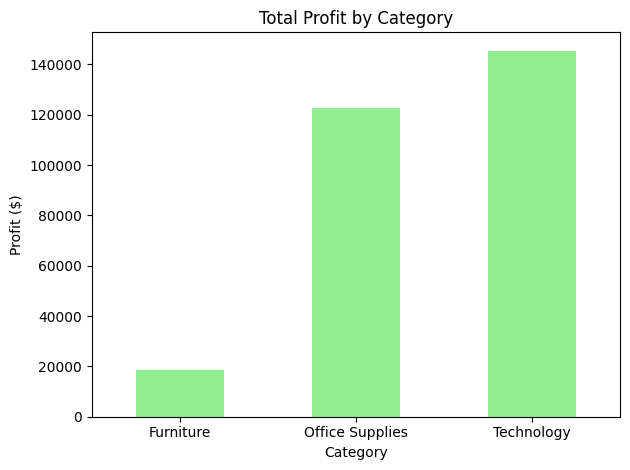

In [44]:
# Calculate total profit for each category
category_profit = store.groupby('Category')['Profit'].sum()

# Plot a simple bar chart
category_profit.plot(kind='bar', color='lightgreen')

# Add basic labels
plt.title('Total Profit by Category')
plt.xlabel('Category')
plt.ylabel('Profit ($)')
plt.xticks(rotation=0)

# Display chart
plt.tight_layout()
plt.show()

In [45]:
profit_by_region = store.groupby('Region')['Profit'].sum().sort_values(ascending=False)
profit_by_region

Region
West       108418.31
East        91522.50
South       46749.49
Central     39706.24
Name: Profit, dtype: float64

C:\Users\apoor\AppData\Local\Temp\ipykernel_25456\2553087456.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=profit_by_region.index, y=profit_by_region.values, palette='viridis')


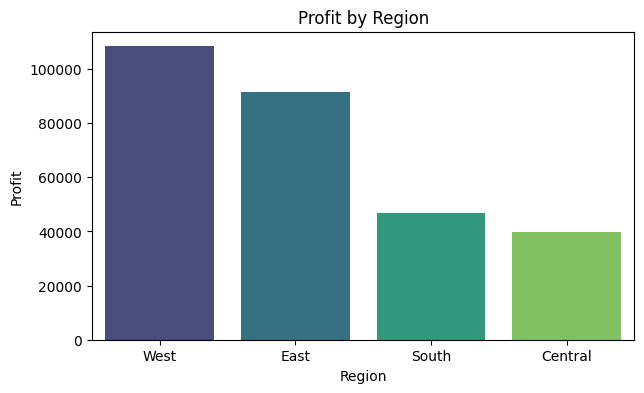

In [46]:
# using seaborn 

plt.figure(figsize=(7, 4))
sns.barplot(x=profit_by_region.index, y=profit_by_region.values, palette='viridis')
plt.title('Profit by Region')
plt.xlabel('Region')
plt.ylabel('Profit')
plt.show()

In [47]:
# monthly sales trend 

monthly_sale = store.groupby('Month').Sales.sum()
monthly_sale

Month
1      94924.87
2      59751.26
3     205005.48
4     137762.13
5     155028.82
6     152718.64
7     147238.07
8     159043.98
9     307649.90
10    200322.97
11    352461.03
12    325293.50
Name: Sales, dtype: float64

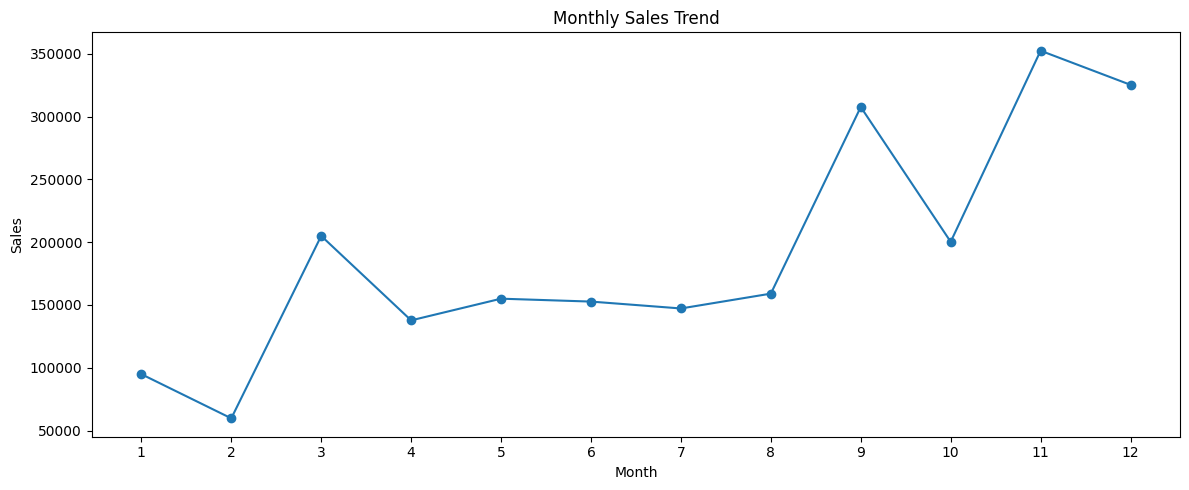

In [48]:
plt.figure(figsize=(12,5))

plt.plot( monthly_sale.index.astype(str), monthly_sale.values, marker='o' )

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales')

plt.tight_layout()
plt.show()

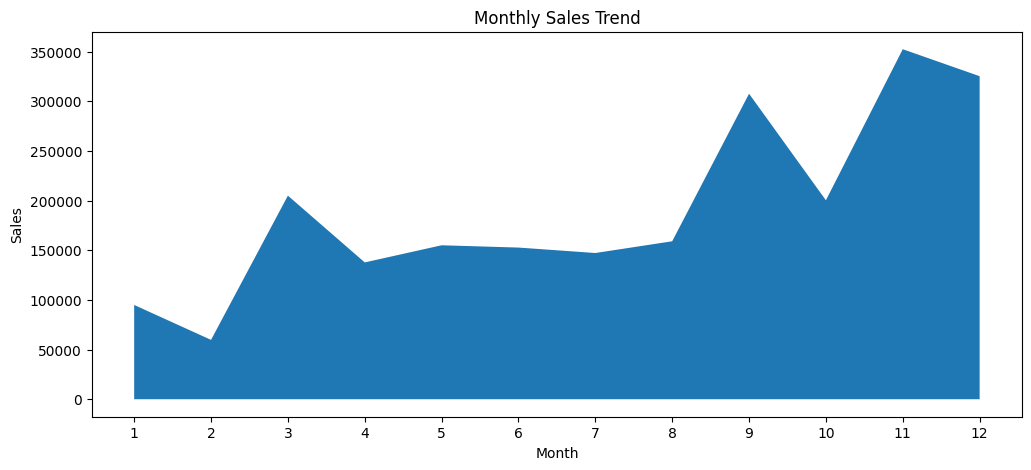

In [49]:
plt.figure(figsize=(12,5))

plt.fill_between( monthly_sale.index.astype(str), monthly_sale.values )
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.show()

In [50]:
# top 10 Products by sales

top_10_products_sales = store.groupby('Product_Name')['Sales'].sum().round(2).sort_values(ascending = False).head(10)
top_10_products_sales

Product_Name
Canon imageCLASS 2200 Advanced Copier                                          61599.83
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.38
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.48
HON 5400 Series Task Chairs for Big and Tall                                   21870.57
GBC DocuBind TL300 Electric Binding System                                     19823.47
GBC Ibimaster 500 Manual ProClick Binding System                               19024.50
Hewlett Packard LaserJet 3310 Copier                                           18839.68
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.89
GBC DocuBind P400 Electric Binding System                                      17965.07
High Speed Automatic Electric Letter Opener                                    17030.31
Name: Sales, dtype: float64

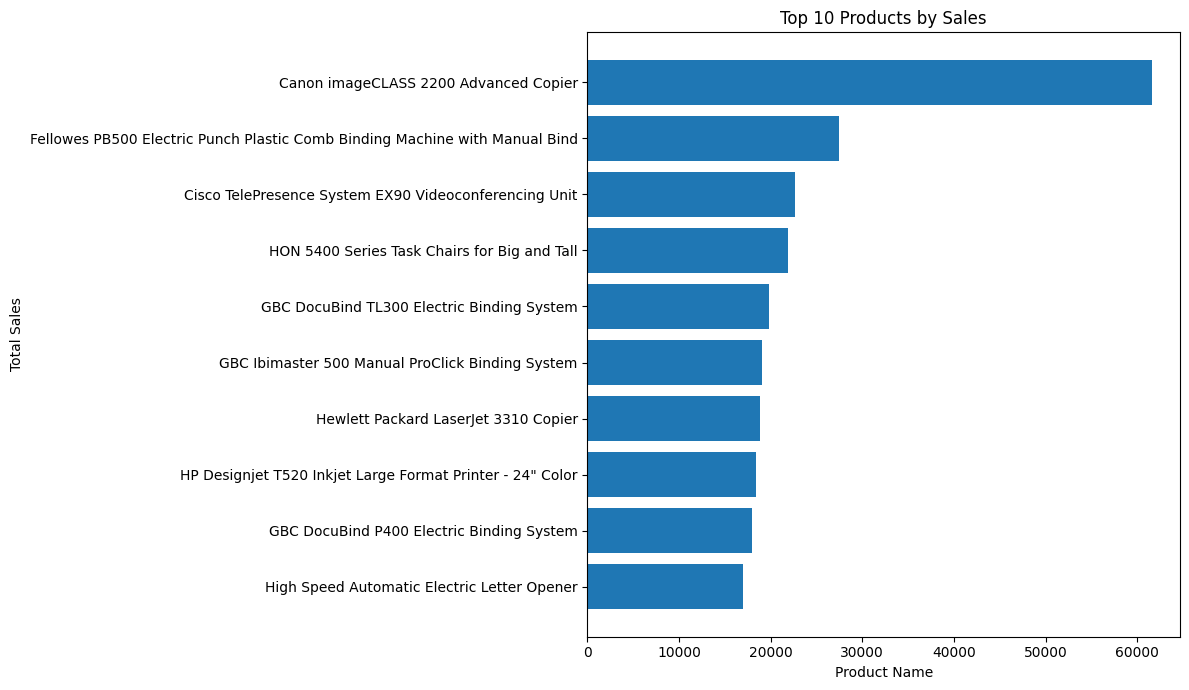

In [51]:
plt.figure(figsize=(12, 7))
plt.barh(top_10_products_sales.index, top_10_products_sales.values)
plt.title('Top 10 Products by Sales')
plt.xlabel('Product Name')
plt.ylabel('Total Sales')
plt.gca().invert_yaxis()  # Highest sales on top
plt.tight_layout()
plt.show()

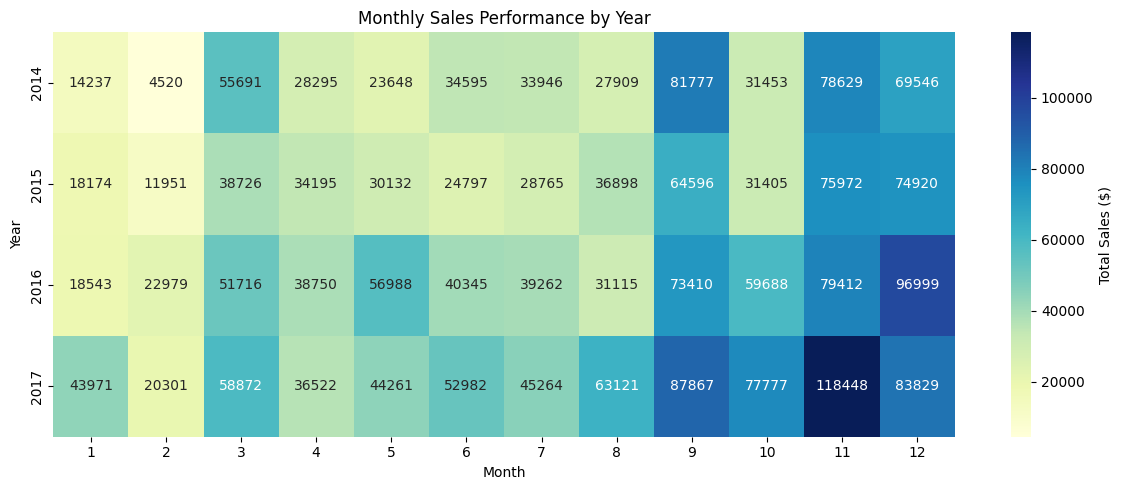

In [52]:
# Pivot data for Year vs. Month
monthly_sales = store.pivot_table(
    index='Year', 
    columns='Month', 
    values='Sales', 
    aggfunc='sum'
)

# Plot heatmap
plt.figure(figsize=(12, 5))
sns.heatmap(monthly_sales, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={'label': 'Total Sales ($)'})
plt.title('Monthly Sales Performance by Year')
plt.xlabel('Month')
plt.ylabel('Year')
plt.tight_layout()
plt.show()

In [53]:
store.pivot_table(index= 'Category' , values = 'Sales', aggfunc = ['sum','mean','min','max','median']).round(2)

,sum,mean,min,max,median
,Sales,Sales,Sales,Sales,Sales
Category,,,,,
Furniture,741999.73,349.83,1.89,4416.17,182.22
Office Supplies,719046.90,119.32,0.44,9892.74,27.42
Technology,836154.02,452.71,0.99,22638.48,166.16


In [54]:
store.pivot_table(index= 'Category' , columns = 'Region', values = 'Sales', aggfunc = ['sum','count'])

sum                                    count        \
Region             Central       East      South       West Central  East   
Category                                                                    
Furniture        163797.14  208291.14  117298.68  252612.77     481   601   
Office Supplies  167026.33  205516.15  125651.26  220853.16    1422  1712   
Technology       170416.29  264974.01  148771.89  251991.83     420   535   

                             
Region          South  West  
Category                     
Furniture         332   707  
Office Supplies   995  1897  
Technology        293   599

---

## Insights of the Superstore Dataset

Below is an executive high-level summary derived from conducting initial EDA on the `Sample - Superstore` dataset.

### 1. Overall Dataset Health
* **Observations & Attributes:** The dataset spans **9,994 transaction rows** across **21 columns**, detailing order profiles, customer segmentation, geography, and financial performance metrics.
* **Completeness:** The dataset is structurally clean with zero null values across critical identifiers, categories, and financial indicators.

### 2. Financial Overview
* **Total Volume & Performance:** Across the full multi-year timeline, the business generated $2,297,200.86 in total sales  and  captured  $286,397.02 in total profit, reflecting an overall corporate profit margin of **12.47%**.
* **Timeline Growth:** The superstore exhibits consistent upward momentum. Annual revenue expanded by over **51.4%** from 2014 ($484.2K) to 2017 ($733.2K), with net profits nearly doubling over the same span.

### 3. Core Category & Regional Discoveries
* **The High-Performers:** **Technology** ($145.4K profit, 17.40% margin) and **Office Supplies** ($122.5K profit, 17.04% margin) serve as the primary financial engines of the business. Geographically, the **West Region** is the most profitable territory, operating at a stellar **14.94% margin**.
* **The Operational Bottlenecks:** While **Furniture** accounts for roughly one-third of total corporate sales ($741.9K), its final profit margin drops to a weak **2.49%**. This is driven by deep promotional discounting on sub-categories like *Tables* (which net a global loss of -$17.7K) and *Bookcases*, alongside severe margin erosion in the **Central Region** (7.92% overall margin).


### 👤 Author & Connect
* **Analyst:** Apoorava Modi
* **LinkedIn:** [www.linkedin.com/in/apoorvmodi](https://www.linkedin.com/in/apoorvmodi)
* **GitHub:** [https://github.com/apoorvmodi?tab=repositories](https://github.com/apoorvmodi?tab=repositories)
---